<a href="https://colab.research.google.com/github/starfgrhtjyjyku/financial-risk-assessment/blob/main/Financial_Risk_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [8]:
from google.colab import files

uploaded = files.upload()

Saving german_credit_data_updated.csv to german_credit_data_updated (1).csv


In [9]:
#Reading with dataset

df = pd.read_csv('german_credit_data_updated.csv')
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,2


**Understanding Data Set**

In [10]:
df.shape

(954, 11)

In [11]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose',
       'Credit Risk'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 954 entries, 0 to 953
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        954 non-null    int64 
 1   Age               954 non-null    int64 
 2   Sex               954 non-null    object
 3   Job               954 non-null    int64 
 4   Housing           954 non-null    object
 5   Saving accounts   779 non-null    object
 6   Checking account  576 non-null    object
 7   Credit amount     954 non-null    int64 
 8   Duration          954 non-null    int64 
 9   Purpose           954 non-null    object
 10  Credit Risk       954 non-null    int64 
dtypes: int64(6), object(5)
memory usage: 82.1+ KB


In [13]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration,Credit Risk
count,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000
mean,476.500000,35.501048,1.909853,3279.112159,20.780922,1.302935
std,275.540378,11.379668,0.649681,2853.315158,12.046483,0.459768
min,0.000000,19.000000,0.000000,250.000000,4.000000,1.000000
25%,238.250000,27.000000,2.000000,1360.250000,12.000000,1.000000
50%,476.500000,33.000000,2.000000,2302.500000,18.000000,1.000000
75%,714.750000,42.000000,2.000000,3975.250000,24.000000,2.000000
max,953.000000,75.000000,3.000000,18424.000000,72.000000,2.000000


In [14]:
df.sample(5)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
671,671,31,male,2,own,moderate,NaN,5742,36,business,1
727,727,25,female,2,rent,little,little,1882,18,radio/TV,2
286,286,26,male,2,own,little,little,4788,48,car,1
191,191,34,male,1,free,moderate,moderate,3844,48,business,2
608,608,33,male,2,own,little,NaN,2051,18,radio/TV,1


**Missing Value Analysis**

In [15]:
df.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,175
Checking account,378
Credit amount,0
Duration,0
Purpose,0


In [16]:
missing = pd.DataFrame(df.isnull().sum(),columns=['Missing Values'])
missing

,Missing Values
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,175
Checking account,378
Credit amount,0
Duration,0
Purpose,0


**Understanding Target Variable**

In [17]:
#Distribution
df['Credit Risk'].value_counts()

,count
Credit Risk,
1,665
2,289


In [18]:
df['Credit Risk'].value_counts(normalize=True)*100

,proportion
Credit Risk,
1,69.706499
2,30.293501


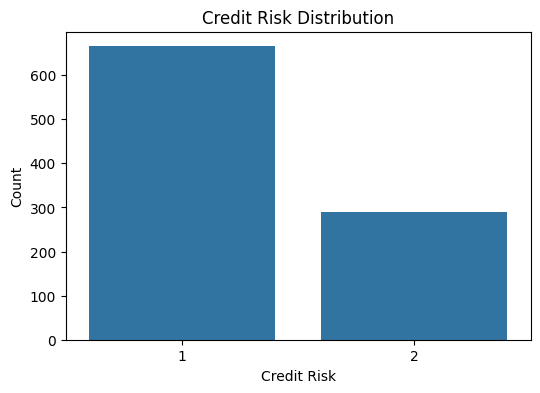

In [19]:
plt.figure(figsize=(6,4))

sns.countplot(x='Credit Risk', data=df)

plt.title('Credit Risk Distribution')
plt.xlabel('Credit Risk')
plt.ylabel('Count')

plt.show()

In [20]:
#Missing Values Analysis

missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': round(df.isnull().mean()*100,2)
})

missing.sort_values('Missing Values', ascending=False)

,Missing Values,Percentage
Checking account,378,39.62
Saving accounts,175,18.34
Unnamed: 0,0,0.00
Sex,0,0.00
Age,0,0.00
Housing,0,0.00
Job,0,0.00
Credit amount,0,0.00
Duration,0,0.00
Purpose,0,0.00


In [21]:
df['Unnamed: 0'].head()
#Unnamed:0 is simply an index, contains no predictive information. Thus, dropping it

df = df.drop('Unnamed: 0', axis=1)

In [22]:
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,49,male,1,own,little,NaN,2096,12,education,1
3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,53,male,2,free,little,little,4870,24,car,2


**Basic EDA**

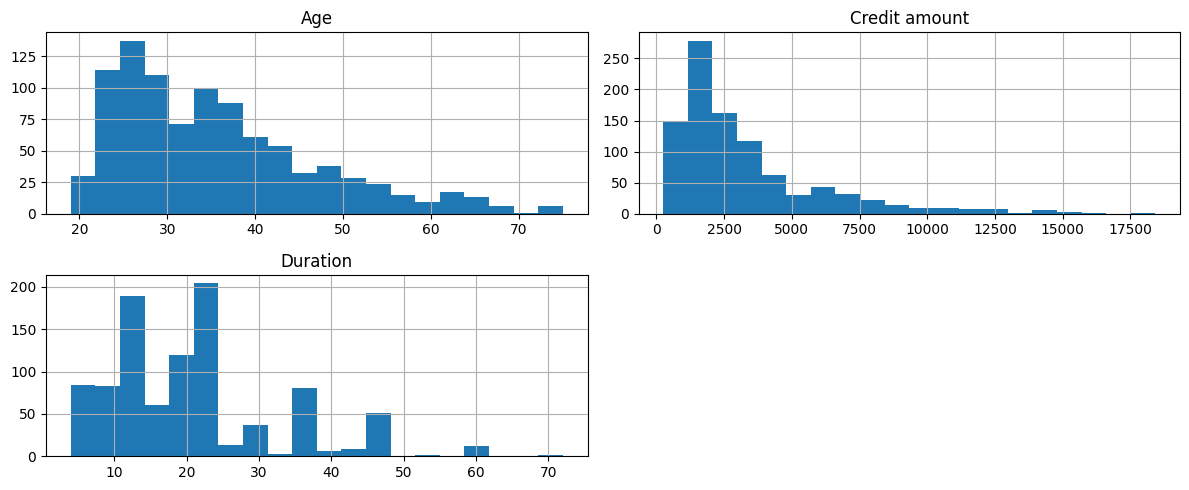

In [23]:
num_cols = ['Age','Credit amount','Duration']
df[num_cols].hist(figsize=(12,5),bins= 20)
plt.tight_layout()
plt.show()

**Target Variables vs Numeric Variables**

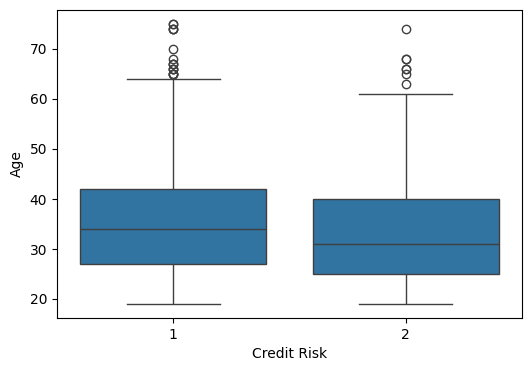

In [24]:
# Age vs Credit Risk
plt.figure(figsize=(6,4))

sns.boxplot(x= 'Credit Risk', y= 'Age', data=df)
plt.show()

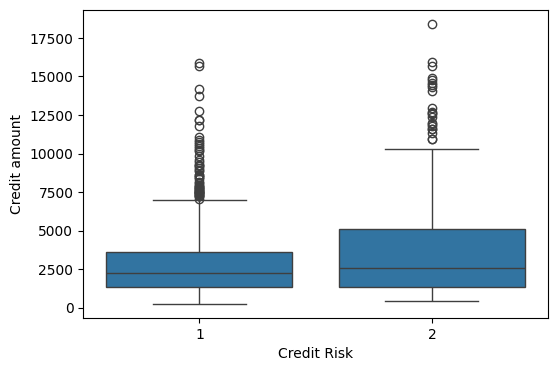

In [25]:
#Credit Amount vs Credit Risk

plt.figure(figsize=(6,4))

sns.boxplot(x= 'Credit Risk', y= 'Credit amount', data=df)
plt.show()

**Data Preprocessing**

In [26]:
#handling Missing Values
##missing values as a separate category ("Unknown") instead of deleting rows.

df['Saving accounts'] = df['Saving accounts'].fillna('Unknown')

df['Checking account'] = df['Checking account'].fillna('Unknown')

In [27]:
df.isnull().sum()

,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,0
Checking account,0
Credit amount,0
Duration,0
Purpose,0
Credit Risk,0


In [28]:
#Checking unique values
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}")
    print(df[col].unique())


Sex
['male' 'female']

Housing
['own' 'free' 'rent']

Saving accounts
['Unknown' 'little' 'quite rich' 'rich' 'moderate']

Checking account
['little' 'moderate' 'Unknown' 'rich']

Purpose
['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']


**Checking Target Meaning**

Verifying which class represents bad credit.

In [29]:
df.groupby('Credit Risk')['Credit amount'].mean()

,Credit amount
Credit Risk,
1,2994.517293
2,3933.975779


In [30]:
df.groupby('Credit Risk')['Duration'].mean()

,Duration
Credit Risk,
1,19.139850
2,24.557093


Class 2 has:

Higher loan amounts
Longer loan durations

This strongly suggests:

1 = Good Credit Risk
2 = Bad Credit Risk

We'll keep that interpretation in the report.

**Data Encoding**

Machine learning models cannot directly process text categories.


Let's convert the target into a more standard binary format.

In [31]:
df['Credit Risk'].value_counts()


,count
Credit Risk,
1,665
2,289


In [32]:
df['Credit Risk'] = df['Credit Risk'].map({
    1: 0,   # Good
    2: 1    # Bad
})

df['Credit Risk'].value_counts()

,count
Credit Risk,
0,665
1,289


*Encoding Categorical Values*

In [33]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_cols = [
    'Sex',
    'Housing',
    'Saving accounts',
    'Checking account',
    'Purpose'
]

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,67,1,2,1,0,1,1169,6,5,0
1,22,0,2,1,1,2,5951,48,5,1
2,49,1,1,1,1,0,2096,12,3,0
3,45,1,2,0,1,1,7882,42,4,0
4,53,1,2,0,1,1,4870,24,1,1


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 954 entries, 0 to 953
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               954 non-null    int64
 1   Sex               954 non-null    int64
 2   Job               954 non-null    int64
 3   Housing           954 non-null    int64
 4   Saving accounts   954 non-null    int64
 5   Checking account  954 non-null    int64
 6   Credit amount     954 non-null    int64
 7   Duration          954 non-null    int64
 8   Purpose           954 non-null    int64
 9   Credit Risk       954 non-null    int64
dtypes: int64(10)
memory usage: 74.7 KB


In [35]:
X = df.drop('Credit Risk', axis=1)

y = df['Credit Risk']

print(X.shape)
print(y.shape)

(954, 9)
(954,)


**Train-test Split**

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(763, 9)
(191, 9)


Feature Scaling

In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)



array([[ 1.70712031,  0.67535685,  0.11745416, ..., -0.35465174,
         0.27880651, -0.93560532],
       [-0.66709819,  0.67535685,  0.11745416, ..., -0.7540189 ,
        -0.71875208,  1.6084676 ],
       [ 1.25053983,  0.67535685, -1.42767554, ..., -0.70039855,
        -0.71875208,  0.59083843],
       ...,
       [-0.484466  ,  0.67535685,  0.11745416, ..., -0.44274232,
        -0.71875208, -0.93560532],
       [ 1.06790763,  0.67535685,  0.11745416, ...,  0.10599582,
         2.27392369,  1.09965301],
       [ 1.25053983,  0.67535685, -1.42767554, ..., -0.63668086,
        -0.21997278,  1.09965301]])

**First Model: Logistic Regression**

In [44]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

**Prediction**

In [45]:
y_pred_lr = lr.predict(X_test_scaled)

y_prob_lr = lr.predict_proba(X_test_scaled)[:,1]

**Evaluation**

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lr))

Accuracy : 0.6910994764397905
Precision: 0.4782608695652174
Recall   : 0.1896551724137931
F1 Score : 0.2716049382716049
ROC-AUC  : 0.6565983925330567


**Confusion Matrix**

In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[121  12]
 [ 47  11]]


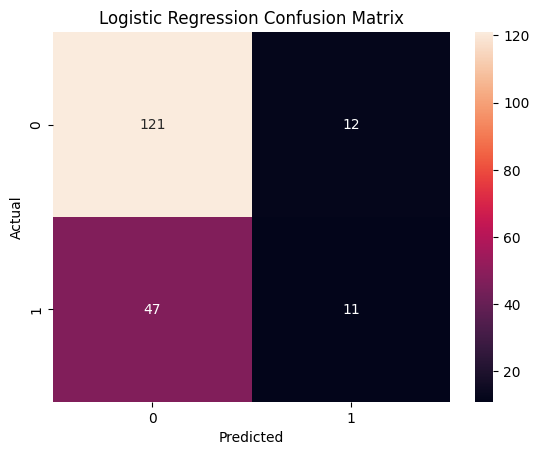

In [48]:
sns.heatmap(cm, annot=True,fmt='d')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [49]:
results = pd.DataFrame({
    'Model':['Logistic Regression'],
    'Accuracy':[accuracy_score(y_test,y_pred_lr)],
    'Precision':[precision_score(y_test,y_pred_lr)],
    'Recall':[recall_score(y_test,y_pred_lr)],
    'F1 Score':[f1_score(y_test,y_pred_lr)],
    'ROC AUC':[roc_auc_score(y_test,y_prob_lr)]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.691099,0.478261,0.189655,0.271605,0.656598


**Random Forest**

In [50]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)

rf.fit(X_train, y_train)
#Notice:

#Use unscaled data for Random Forest.

RandomForestClassifier(n_estimators=200, random_state=42)

In [51]:
y_pred_rf = rf.predict(X_test)

y_prob_rf = rf.predict_proba(X_test)[:,1]

In [52]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf))

Accuracy : 0.7225130890052356
Precision: 0.5581395348837209
Recall   : 0.41379310344827586
F1 Score : 0.4752475247524752
ROC-AUC  : 0.7740471869328494


[[114  19]
 [ 34  24]]


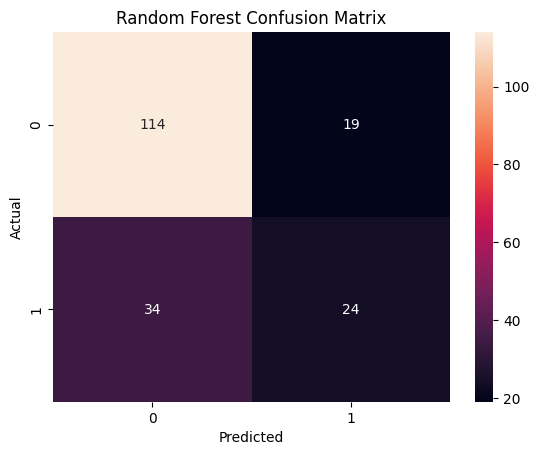

In [53]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

**Feature Importance Analysis**

Before moving to Gradient Boosting, let's see which variables are most influential.

In [54]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
6,Credit amount,0.259547
0,Age,0.176349
7,Duration,0.145260
5,Checking account,0.138687
8,Purpose,0.082868
4,Saving accounts,0.066844
2,Job,0.054492
3,Housing,0.044962
1,Sex,0.030992


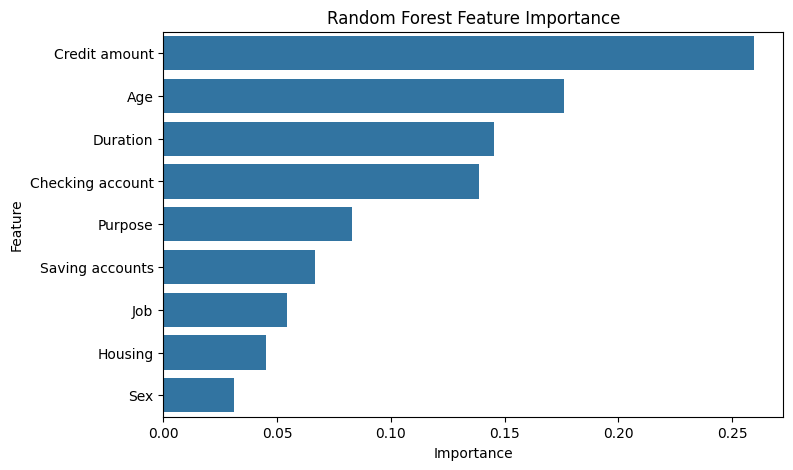

In [55]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')

plt.show()

**Gradient Boosting **

In [56]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42
)

gb.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)

In [58]:
y_pred_gb = gb.predict(X_test)

y_prob_gb = gb.predict_proba(X_test)[:,1]

In [59]:
print("Accuracy :", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall   :", recall_score(y_test, y_pred_gb))
print("F1 Score :", f1_score(y_test, y_pred_gb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_gb))

Accuracy : 0.743455497382199
Precision: 0.6153846153846154
Recall   : 0.41379310344827586
F1 Score : 0.4948453608247423
ROC-AUC  : 0.7634171635986517


[[118  15]
 [ 34  24]]


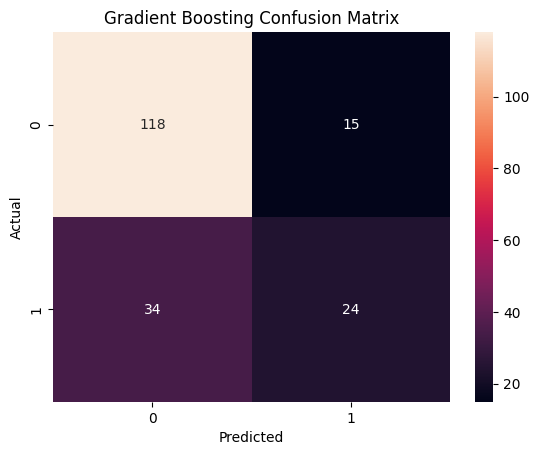

In [60]:
cm_gb = confusion_matrix(y_test, y_pred_gb)

print(cm_gb)

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d'
)

plt.title('Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()